   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 15.6 MB/s eta 0:00:00
3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


/tmp/ipykernel_5737/560065398.py:52: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


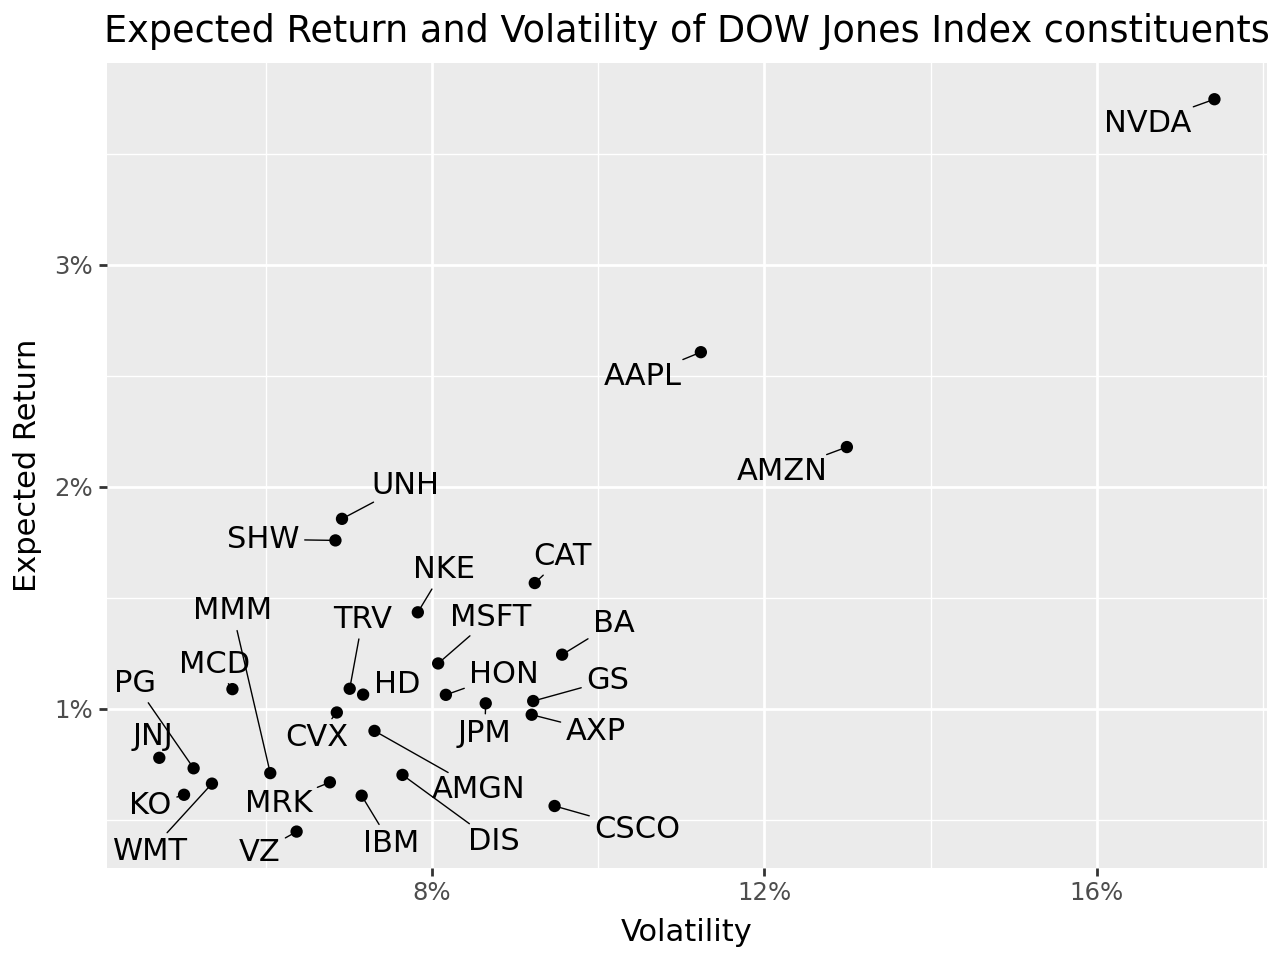

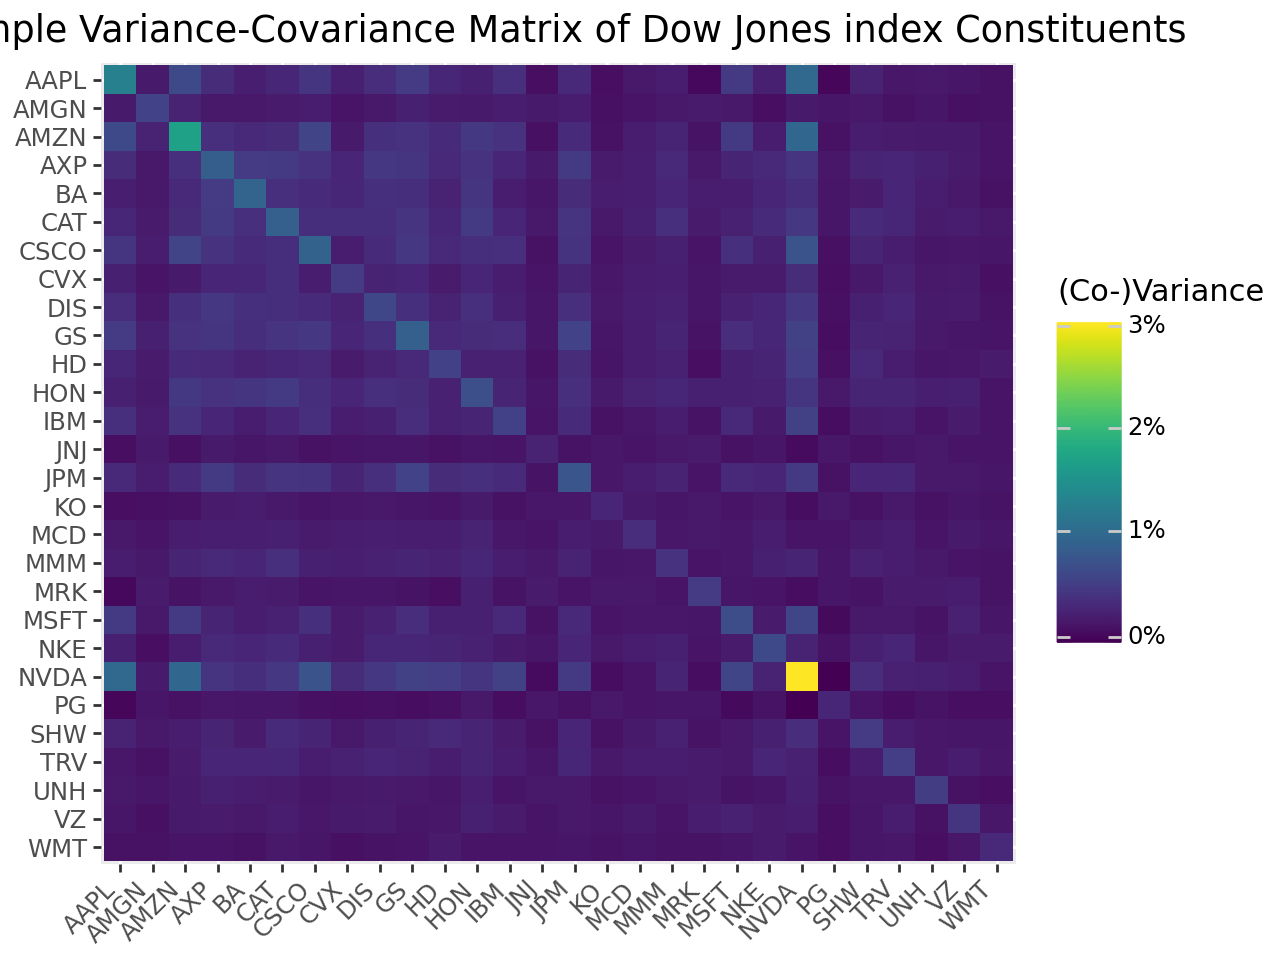

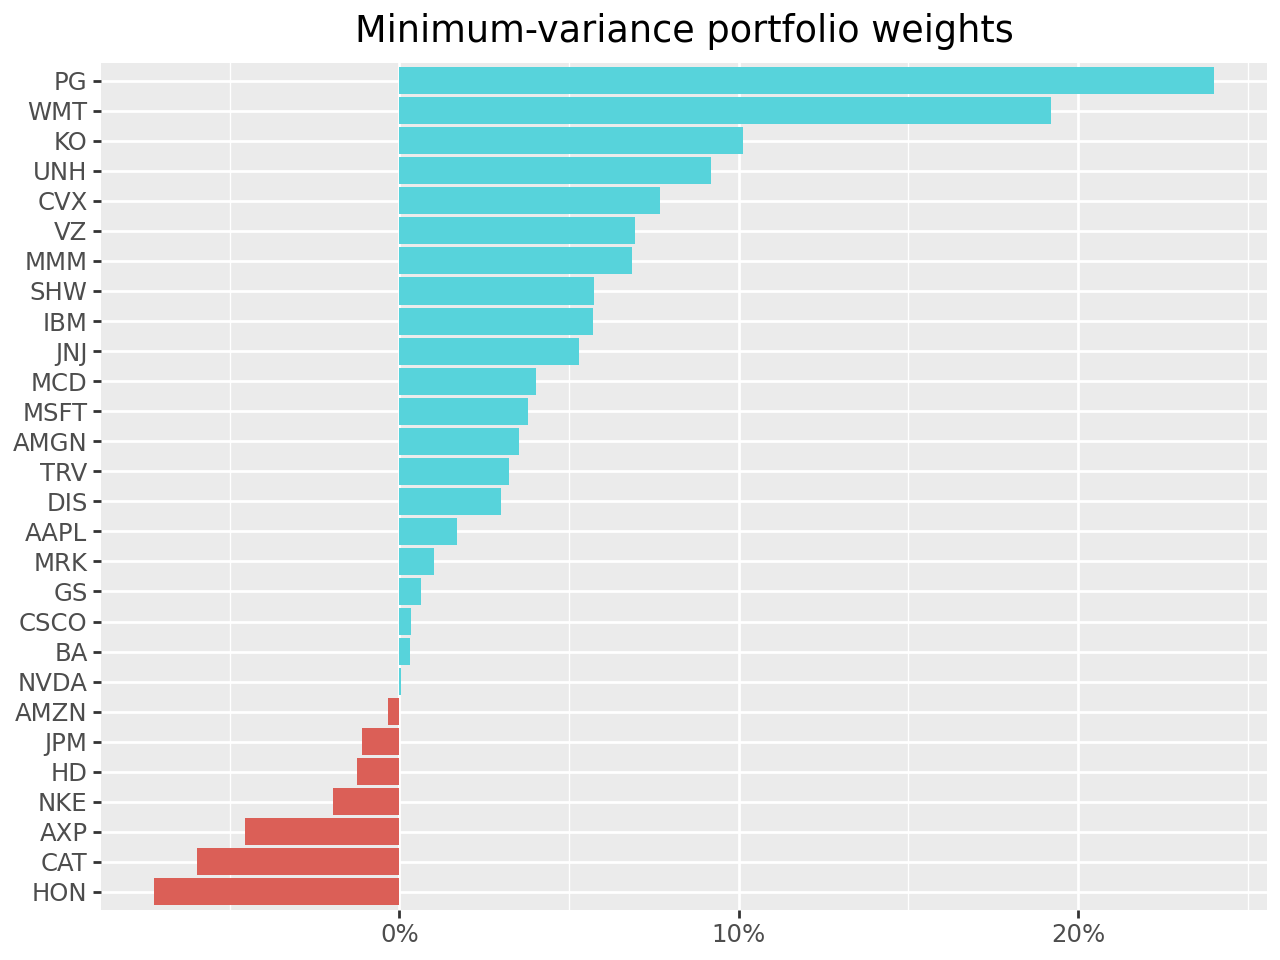

Index(['MMM', 'DIS', 'CSCO', 'IBM', 'HD', 'VZ', 'MRK', 'GS', 'HON', 'AXP',
       'WMT', 'CVX', 'KO', 'AMGN', 'JPM', 'MSFT', 'PG', 'AMZN', 'NVDA', 'TRV',
       'BA', 'NKE', 'AAPL', 'CAT', 'MCD', 'JNJ', 'UNH', 'SHW'],
      dtype='object', name='symbol')
   symbol        mu     sigma  omega_mvp  omega_efp
0     MMM  0.007095  0.060555   0.068629  -0.531849
1     DIS  0.007014  0.076463   0.029949  -0.389435
2    CSCO  0.005613  0.094761   0.003394  -0.297640
3     IBM  0.006077  0.071552   0.057047  -0.242004
4      HD  0.010634  0.071725  -0.012586  -0.234614
5      VZ  0.004460  0.063724   0.069369  -0.214728
6     MRK  0.006681  0.067729   0.010315  -0.146434
7      GS  0.010344  0.092188   0.006380  -0.124359
8     HON  0.010623  0.081682  -0.072366  -0.102728
9     AXP  0.009726  0.092009  -0.045418  -0.101089
10    WMT  0.006621  0.053539   0.192014  -0.008393
11    CVX  0.009828  0.068562   0.076681  -0.002049
12     KO  0.006119  0.050181   0.101379   0.023091
13   AMGN  0.0089

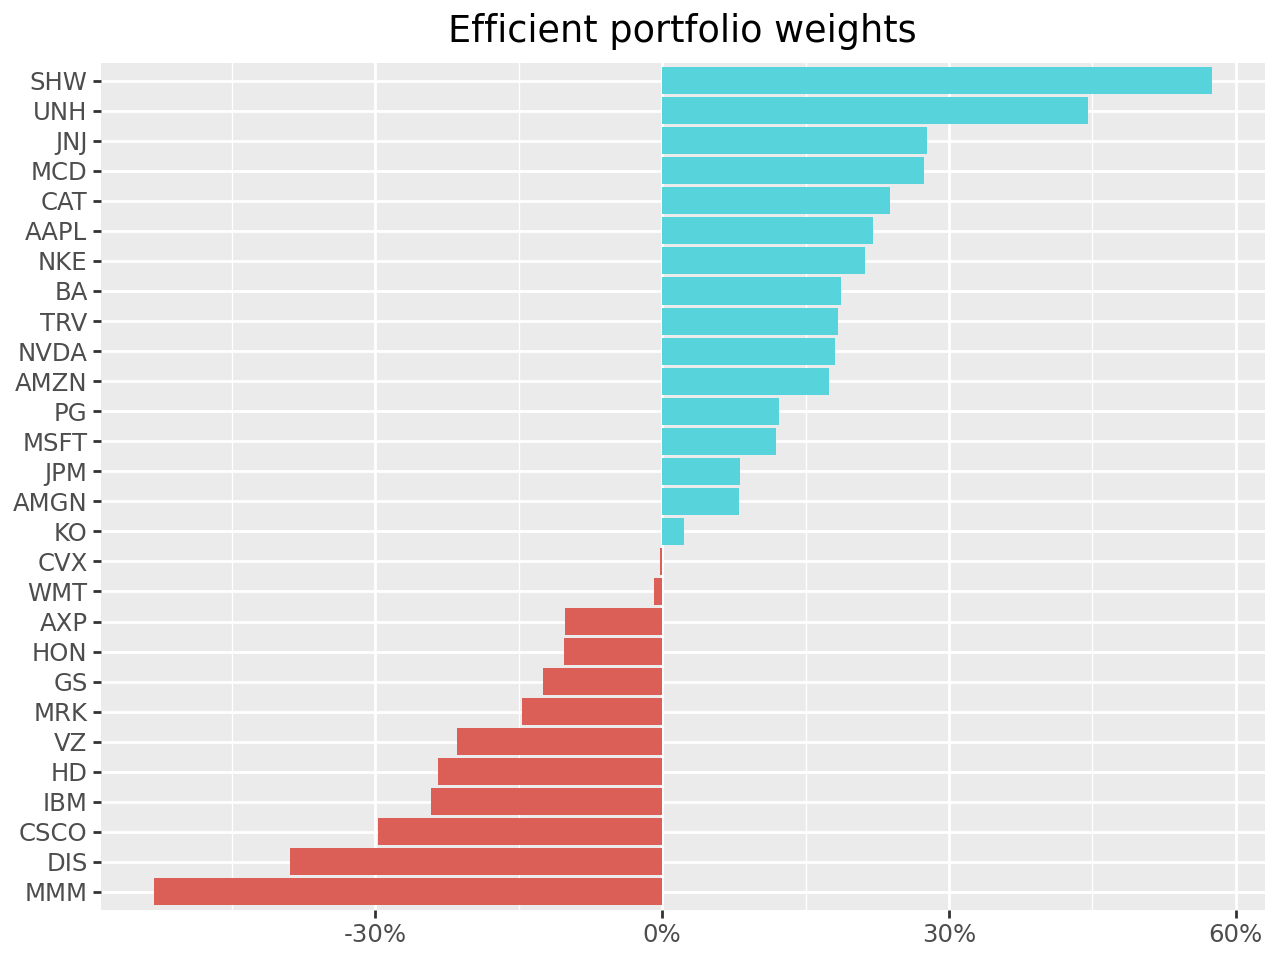

/usr/local/lib/python3.12/dist-packages/plotnine/layer.py:364: PlotnineWarning: geom_label : Removed 28 rows containing missing values.


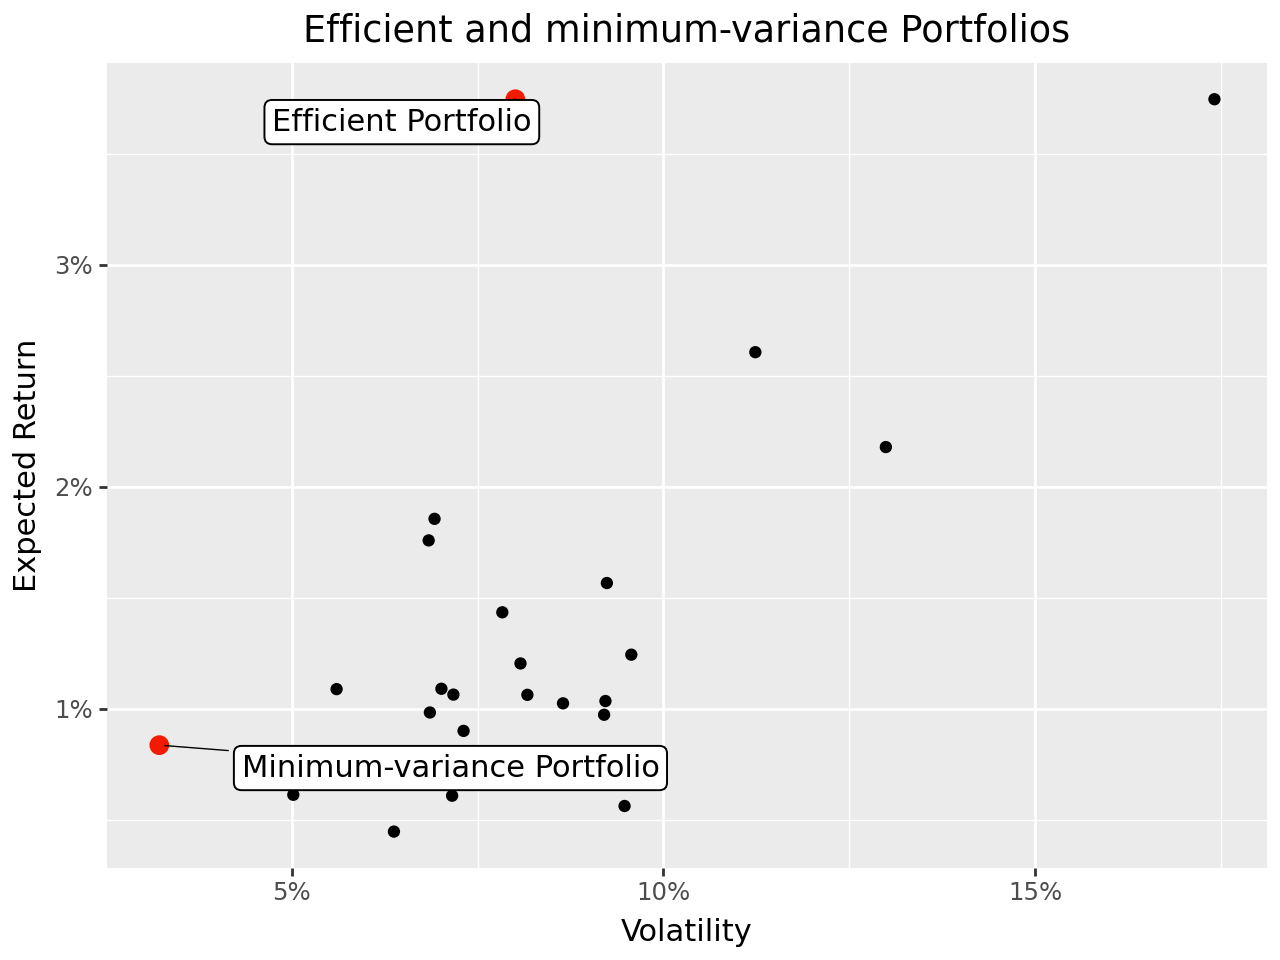

/usr/local/lib/python3.12/dist-packages/plotnine/layer.py:364: PlotnineWarning: geom_label : Removed 329 rows containing missing values.


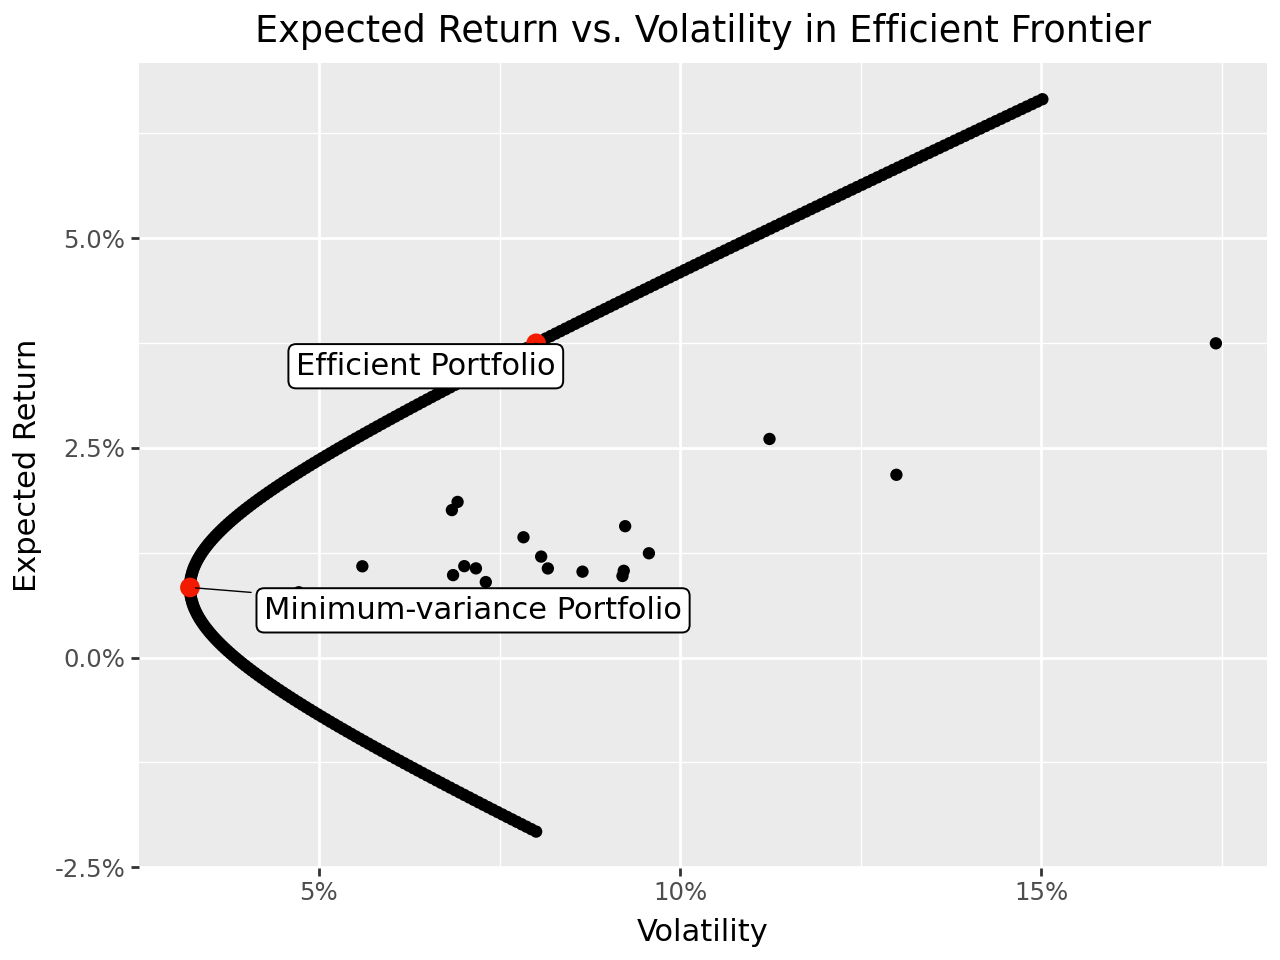

In [ ]:
!pip install -q tidyfinance
!pip install -q adjustText

import sys
print(sys.version)

import pandas as pd
import numpy as np
import tidyfinance as tf

from plotnine import *
from mizani.formatters import percent_format
from adjustText import adjust_text

#adjust_text is used to add labels to figures

#we need to answer the question of how to balance risk/volatility with expected
#returns (and how to distribute our wealth across multiple investments)

#portfolio risk relies on the volatility of individual assets, and the correlation between assets' returns
#so, we can combine assets w/ low or negative correlations to reduce risk
#fruit basket analogy: when keeping a basket with all apples, they will spoil all at once;
#if you have a basket with different kinds of fruits, some may spoil while others stay fresh

#mean variance analysis: evaluates portfolios based on expected return and risk,
#defined as the variance of portolio returns
#investors balance these variables in two ways: minimize risk at a set expected return,
#or maximize expected return at a set risk

#there are N risky investments, each asset i delivers mu_i expected returns over a set period
#the investor allocates portfolio weights omega_i to each asset, summing to 1

#investing happens in two phases: 1) establish expected risk/returns based on data (in this case, historical)
#and 2) deciding portfolio weights based on this data

#we will assume historical data is the true distribution of expected returns and variance

symbols = tf.download_data(
    domain = "constituents",
    index = "Dow Jones Industrial Average"
)

prices_daily = tf.download_data(
    domain = 'stock_prices',
    symbols = symbols['symbol'].tolist(),
    start_date = '2000-01-01',
    end_date = '2023-12-31'
)

prices_daily = (prices_daily
    .groupby('symbol')
    .apply(lambda x: x.assign(counts=x['adjusted_close'].dropna().count()))
    .reset_index(drop=True)
    .query('counts == counts.max()')
)

#.groupby('symbol) groups the df by symbol (essentially creating mini DFs) so we can run functions by stock
#.apply and .assign creates a new column where the value is the number of days the stock was traded (values are the same across days for the same stock)
#we then only keep rows (stocks) that were traded across the whole period, bc if they aren't that's inviting instability
#we do this by checking counts == counts.max() (individual symbol 'count' equals the max value in counts, presumably the entire period)

returns_monthly = (
    prices_daily
    .assign(
        date = lambda x: x['date'].dt.to_period('M').dt.to_timestamp()
    )
    .groupby(['symbol','date'], as_index = False)
    .agg(adjusted_close=('adjusted_close','last'))
    .assign(ret=lambda x: x.groupby('symbol')['adjusted_close'].pct_change())
)

#computing sample standard deviation to calculate variance and volatility
#volatility = sigma, variance = sigma^2

assets = (
    returns_monthly
    .groupby('symbol', as_index = False)
    .agg(
        mu = ('ret','mean'),
        sigma = ('ret','std')
    )
)

assets_figure = (
    ggplot(
        assets, aes(x='sigma',y='mu',label = 'symbol')
    )
    + geom_point()
    + geom_text(adjust_text={'arrowprops': {'arrowstyle': '-'}})
    + scale_x_continuous(labels=percent_format())
    + scale_y_continuous(labels=percent_format())
    + labs(
        x='Volatility', y='Expected Return',
        title='Expected Return and Volatility of DOW Jones Index constituents'
    )
)
assets_figure.show()

#now we use a variance-covariance matrix to consider interactions between assets
#a positive covariance indicates assets are moving in the same direction, a negative covariance indicates the opposite
#but to use this matrix, we need to convert our returns into a [TxN] matrix,
#with each row representing a symbol and each column representing a trading day

returns_wide = (
    returns_monthly
    .pivot(index='date', columns='symbol', values='ret')
    .reset_index()
)

sigma = (
    returns_wide
    .drop(columns=['date'])
    .cov()
)

#.pivot() converts long form (DF) to wide form (matrix)

sigma_long = (
    sigma
    .reset_index()
    .melt(id_vars='symbol', var_name='symbol_b', value_name='value')
)

#.melt() keeps the column 'symbol' while creating a new column 'symbol_b' that takes the melted column names (symbols)
#then it creates a new column 'value'  which holds the melted values in each column

sigma_long['symbol_b'] = pd.Categorical(
    sigma_long['symbol_b'],
    categories=sigma_long['symbol_b'].unique()[::-1],
    ordered = True
)

sigma_figure = (
    ggplot(
        sigma_long,
        aes(x='symbol',y='symbol_b',fill='value')
    )
    + geom_tile()
    + labs(x='',y='',fill='(Co-)Variance', title='Sample Variance-Covariance Matrix of Dow Jones index Constituents')
    + scale_fill_continuous(labels=percent_format())
    + theme(axis_text_x=element_text(angle=45, hjust=1))
)
sigma_figure.show()

#given the weight is omega_i, then the return for each investment is omega_i * mu_i
#we take the sum of each investment to compute the expected return of the entire investment
#using some linear algebra formulas (which i wont pretend to understand), we know that:
#portfolio variance = sum(sum(omega_i * omega_j * sigma_ij)), where sigma_ij = covariance between the two assets
#this formula calculates the variance of each individual asset and the covariance between them, accounting for any relation in assets
#so, to minimize variance at a particular reference point, we just solve the minimization equation
#min(omega) of omega_prime*(covariance matrix)*omega
#we calculate this with N = sum(omega_i) = 1, meaning we are fully invested

#now we calculate the solution to this problem using another provided formula

iota = np.ones(sigma.shape[0])
sigma_inv = np.linalg.inv(sigma.values)
omega_mvp = (sigma_inv @ iota) / (iota @ sigma_inv @ iota)

assets = assets.assign(omega_mvp=omega_mvp)

assets['symbol'] = pd.Categorical(
    assets['symbol'],
    categories = assets.sort_values('omega_mvp')['symbol'],
    ordered = True
)

#this sorts the 'symbol' column in assets in order of portfolio weight (dependent on variance),
#and does this by making it categorical and saying to keep this specific order

omega_figure = (
    ggplot(
        assets, aes(y='omega_mvp', x='symbol', fill='omega_mvp>0')
    )
    + geom_col()
    + coord_flip()
    + scale_y_continuous(labels=percent_format())
    + labs(x='',y='', title='Minimum-variance portfolio weights')
    + theme(legend_position='none')
)
omega_figure.show()

#geom_col() creates a bar graph, and coord_flip() just rotates it (so weights are on x axis)
#we get negative weights to represent how much to SHORT stocks, often minimizing variance by diversifying a portfolio

mu = assets['mu'].values
mu_mvp = omega_mvp @ mu
sigma_mvp = np.sqrt(omega_mvp @ sigma.values @ omega_mvp)
summary_mvp = pd.DataFrame(
    {
        'mu': [mu_mvp],
        'sigma': [sigma_mvp],
        'type': ['Minimum-variance Portfolio'],
    }
)

#this creates a 1d matrix of mu, the expected returns of each asset
#it then calculates mu_mvp, the total expected return of the portfolio
#then it calculates sigma_mvp, the volatility of the portfolio (where volatility equals the sqrt(variance))

#often investors are willing to accept more risk (higher volatility) in exchange for a greater expected return
#we might express this as setting mu_bar (the target expected return) to the
#historical average return that provided the highest average return in the past

mu_bar = assets['mu'].max()

#now, the problem looks like:
#min(omega_prime @ covariance matrix @ omega) for omega (minimize variance)
#such that omega_prime @ iota = 1 (we are fully invested)
#and omega_prime @ mu >= mu_bar

#now we use a formula to find weights (it's over my head)

C = iota @ sigma_inv @ iota
D = iota @ sigma_inv @ mu
E = mu @ sigma_inv @ mu
lambda_tilde = 2 * (mu_bar - D / C) / (E - (D**2) / C)
omega_efp = omega_mvp + (lambda_tilde / 2) * (sigma_inv @ mu - D * omega_mvp)
mu_efp = omega_efp @ mu
sigma_efp = np.sqrt(omega_efp @ sigma.values @ omega_efp)

summary_efp = pd.DataFrame(
    {'mu': [mu_efp], 'sigma': [sigma_efp], 'type': ['Efficient Portfolio']}
)

assets = assets.assign(omega_efp=omega_efp)

sort_col = 'omega_efp'
assets = assets.sort_values(sort_col, ascending=True).reset_index(drop=True)

assets['symbol'] = pd.Categorical(
    assets['symbol'].astype(str),
    categories = assets['symbol'].astype(str),
    ordered = True
)

print(assets['symbol'].cat.categories)
print(assets)

omega_figure_efp = (
    ggplot(
        assets, aes(y=sort_col, x='symbol', fill=f'{sort_col}>0')
    )
    + geom_col()
    + coord_flip()
    + scale_y_continuous(labels=percent_format())
    + labs(x='',y='', title='Efficient portfolio weights')
    + theme(legend_position='none')
)
omega_figure_efp.show()

summaries = pd.concat([assets, summary_mvp, summary_efp], ignore_index = True)

summaries_figure = (
    ggplot(summaries, aes(x='sigma',y='mu'))
    + geom_point(data=summaries.query('type.isna()'))
    + geom_point(data=summaries.query('type.notna()'), color='#F21A00', size=3)
    + geom_label(
        aes(label='type'), adjust_text={'arrowprops': {'arrowstyle': '-'}}
    )
    + scale_x_continuous(labels=percent_format())
    + scale_y_continuous(labels=percent_format())
    + labs(x = 'Volatility', y = 'Expected Return', title='Efficient and minimum-variance Portfolios')
)
summaries_figure.show()

#efficient frontier = the set of portfolios that maximizes expected return at each potential level of risk
#Mutual Fund Separation Theorem: we can find the efficient frontier by combining the efficient portfolio with the minimum-risk portfolio
#equation:
#omega_(a*mu_1 + (1-a)*mu_2) = a*omega_mu_1 + (1-a)*omega_mu_2
#a is a scalar  between 0 and 1 (representing how much of each portfolio is represented)
#omega_mu_i is the efficient portfolio with expected returns mu_i

efficient_frontier = (
    pd.DataFrame({'a': np.arange(-1,2.01,0.01)})
    .assign(
        omega=lambda x: x['a'].map(
            lambda x: x * omega_efp + (1-x) * omega_mvp
        )
    )
    .assign(
        mu=lambda x: x['omega'].map(lambda x: x @ mu),
        sigma=lambda x: x['omega'].map(lambda x: np.sqrt(x @ sigma @ x))
    )
)

summaries = pd.concat([summaries, efficient_frontier], ignore_index=True)

summaries_figure = (
    ggplot(summaries, aes(x='sigma',y='mu'))
    + geom_point(data=summaries.query('type.isna()'))
    + geom_point(data=summaries.query('type.notna()'),color='#F21A00', size=3)
    + geom_label(
        aes(label='type'), adjust_text={'arrowprops': {'arrowstyle':'-'}}
    )
    + scale_x_continuous(labels=percent_format())
    + scale_y_continuous(labels=percent_format())
    + labs(
        x='Volatility', y='Expected Return', title='Expected Return vs. Volatility in Efficient Frontier'
    )
)
summaries_figure.show()